In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, models, transforms
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
import time
import pandas as pd
import copy

#random seed
seed = 42
torch.manual_seed(seed)
torch.cuda.manual_seed(seed)

# ngecek device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [2]:
weights = models.ResNet18_Weights.IMAGENET1K_V1

#data train
train_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=weights.transforms().mean, std=weights.transforms().std)
])

#data validasi: hanya deterministik tanpa distorsi
eval_transforms = weights.transforms()

In [3]:
#download dataset polos pake eval_transform
dataset_full = datasets.OxfordIIITPet(root='./data', split='trainval', download=True, transform=eval_transforms)

#ambil 10 kelas dengan index 0-9
kelas_pilihan = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

#ngumpulin gambar dari 10 kelas
index_terpilih = []
label_terpilih = []
for i in range(len(dataset_full)):
    if dataset_full._labels[i] in kelas_pilihan:
        index_terpilih.append(i)
        label_terpilih.append(dataset_full._labels[i])

#70% train, 30% sisa
idx_train, idx_sisa, label_train, label_sisa = train_test_split(
    index_terpilih, label_terpilih, test_size=0.3, stratify=label_terpilih, random_state=seed
)

#15% val, 15% test
idx_val, idx_test = train_test_split(
    idx_sisa, test_size=0.5, stratify=label_sisa, random_state=seed
)

print(f"Data Train: {len(idx_train)}, Validasi: {len(idx_val)}, Test: {len(idx_test)}")

100%|██████████| 792M/792M [00:38<00:00, 20.8MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 10.2MB/s]


Data Train: 697, Validasi: 149, Test: 150


In [4]:
def hitung_parameter(model):
    #verifikasi parameter
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total_params = sum(p.numel() for p in model.parameters())
    return trainable_params, total_params

def buat_model_B1():
    model = models.resnet18(weights=None)
    model.fc = nn.Linear(model.fc.in_features, 10)
    return model

def buat_model_B2():
    model = models.resnet18(weights=weights)

    for param in model.parameters():
        param.requires_grad = False

    num_features = model.fc.in_features
    model.fc = nn.Linear(num_features, 10)
    return model

def buat_model_B3_B4():
    model = models.resnet18(weights=weights)
    for param in model.parameters():
        param.requires_grad = False

    for param in model.layer4.parameters():
        param.requires_grad = True

    num_features = model.fc.in_features
    model.fc = nn.Linear(num_features, 10)
    return model

def buat_model_B5():
    model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
    num_features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(num_features, 10)
    return model

In [5]:
def latih_model(model, loader_train, loader_val, optimizer, nama_eksperimen):
    criterion = nn.CrossEntropyLoss()
    max_epochs = 15
    patience = 3

    best_loss = float('inf')
    best_val_acc = 0.0
    counter_sabar = 0
    best_model_wts = copy.deepcopy(model.state_dict())
    waktu_mulai = time.time()
    epoch_konvergen = 0

    print(f"\n--- Latih: {nama_eksperimen} ---")
    for epoch in range(max_epochs):
        #train
        model.train()
        loss_train = 0.0
        for inputs, labels in loader_train:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            loss_train += loss.item() * inputs.size(0)

        loss_train = loss_train / len(loader_train.dataset)

        #val
        model.eval()
        loss_val = 0.0
        benar_val = 0
        total_val = 0
        with torch.no_grad():
            for inputs, labels in loader_val:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                loss_val += loss.item() * inputs.size(0)

                tebakan = torch.argmax(outputs, dim=1)
                benar_val += (tebakan == labels).sum().item()
                total_val += labels.size(0)

        loss_val = loss_val / len(loader_val.dataset)
        acc_val = benar_val / total_val

        print(f"Epoch {epoch+1:2d} | Train Loss: {loss_train:.4f} | Val Loss: {loss_val:.4f} | Val Acc: {acc_val:.4f}")

        #early stopping
        if loss_val < best_loss:
            best_loss = loss_val
            best_val_acc = acc_val
            best_model_wts = copy.deepcopy(model.state_dict())
            counter_sabar = 0
            epoch_konvergen = epoch + 1
        else:
            counter_sabar += 1
            if counter_sabar >= patience:
                print(f"-> Stop di epoch {epoch+1}. Model terbaik disimpan dari Epoch {epoch_konvergen}.")
                break

    waktu_selesai = time.time() - waktu_mulai
    model.load_state_dict(best_model_wts)
    return model, epoch_konvergen, best_val_acc, waktu_selesai

In [6]:
def uji_model(model, loader_test):
    model.eval()
    prediksi_semua = []
    label_semua = []
    benar = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in loader_test:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            tebakan = torch.argmax(outputs, dim=1)

            prediksi_semua.extend(tebakan.cpu().numpy())
            label_semua.extend(labels.cpu().numpy())

            benar += (tebakan == labels).sum().item()
            total += labels.size(0)

    akurasi = benar / total
    f1 = f1_score(label_semua, prediksi_semua, average='macro')
    return akurasi, f1

In [7]:
import os

if os.path.exists("catatan_metrik_mentah.csv"):
    os.remove("catatan_metrik_mentah.csv")

hasil_akhir = []
daftar_uji = ["B1", "B2", "B3", "B4_Tanpa_Aug", "B4_Dengan_Aug", "B5"]

loader_val = DataLoader(Subset(dataset_full, idx_val), batch_size=32, shuffle=False)
loader_test = DataLoader(Subset(dataset_full, idx_test), batch_size=32, shuffle=False)

for kode in daftar_uji:
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)

    print(f"\n{'='*40}")

    if kode == "B1":
        model = buat_model_B1().to(device)
        dataset_train = Subset(dataset_full, idx_train)
        optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
        info_lr = "1e-3"

    elif kode == "B2":
        model = buat_model_B2().to(device)
        dataset_train = Subset(dataset_full, idx_train)
        optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-3, weight_decay=1e-2)
        info_lr = "1e-3"

    elif kode in ["B3", "B4_Tanpa_Aug"]:
        model = buat_model_B3_B4().to(device)
        dataset_train = Subset(dataset_full, idx_train)
        optimizer = torch.optim.AdamW([
            {"params": model.layer4.parameters(), "lr": 1e-4},
            {"params": model.fc.parameters(), "lr": 1e-3},
        ], weight_decay=1e-2)
        info_lr = "layer4: 1e-4, fc: 1e-3"

    elif kode == "B4_Dengan_Aug":
        model = buat_model_B3_B4().to(device)
        dataset_aug = datasets.OxfordIIITPet(root='./data', split='trainval', transform=train_transforms)
        dataset_train = Subset(dataset_aug, idx_train)
        optimizer = torch.optim.AdamW([
            {"params": model.layer4.parameters(), "lr": 1e-4},
            {"params": model.fc.parameters(), "lr": 1e-3},
        ], weight_decay=1e-2)
        info_lr = "layer4: 1e-4, fc: 1e-3"

    elif kode == "B5":
        model = buat_model_B5()
        for param in model.parameters():
            param.requires_grad = False
        for param in model.features[-1].parameters():
            param.requires_grad = True
        for param in model.classifier.parameters():
            param.requires_grad = True
        model = model.to(device)

        dataset_aug = datasets.OxfordIIITPet(root='./data', split='trainval', transform=train_transforms)
        dataset_train = Subset(dataset_aug, idx_train)
        optimizer = torch.optim.AdamW([
            {"params": model.features[-1].parameters(), "lr": 1e-4},
            {"params": model.classifier.parameters(), "lr": 1e-3},
        ], weight_decay=1e-2)
        info_lr = "features: 1e-4, classifier: 1e-3"

    loader_train = DataLoader(dataset_train, batch_size=32, shuffle=True)
    param_dilatih, param_total = hitung_parameter(model)

    model, epoch_stop, akurasi_val, waktu = latih_model(model, loader_train, loader_val, optimizer, kode)

    #nguji model ke dataset
    akurasi_test, f1_test = uji_model(model, loader_test)

    hasil_akhir.append({
        "Kode Eksperimen": kode,
        "Trainable Parameters": param_dilatih,
        "Learning Rate": info_lr,
        "Epoch hingga Konvergen": epoch_stop,
        "Durasi Pelatihan Total (detik)": round(waktu, 2),
        "Akurasi Validasi": round(akurasi_val, 4),
        "Macro F1-Score (Test Set)": round(f1_test, 4)
    })

df_hasil = pd.DataFrame(hasil_akhir)
df_hasil.to_csv("catatan_metrik_mentah.csv", index=False)



--- Latih: B1 ---
Epoch  1 | Train Loss: 2.3846 | Val Loss: 12.1485 | Val Acc: 0.1544
Epoch  2 | Train Loss: 2.0357 | Val Loss: 2.0737 | Val Acc: 0.2752
Epoch  3 | Train Loss: 1.9020 | Val Loss: 2.1724 | Val Acc: 0.2483
Epoch  4 | Train Loss: 1.7830 | Val Loss: 1.9008 | Val Acc: 0.3087
Epoch  5 | Train Loss: 1.6791 | Val Loss: 2.0949 | Val Acc: 0.3289
Epoch  6 | Train Loss: 1.5912 | Val Loss: 2.0300 | Val Acc: 0.3221
Epoch  7 | Train Loss: 1.5225 | Val Loss: 1.8448 | Val Acc: 0.3758
Epoch  8 | Train Loss: 1.4152 | Val Loss: 2.0002 | Val Acc: 0.3356
Epoch  9 | Train Loss: 1.2998 | Val Loss: 3.0245 | Val Acc: 0.2886
Epoch 10 | Train Loss: 1.2808 | Val Loss: 1.8215 | Val Acc: 0.3893
Epoch 11 | Train Loss: 1.1929 | Val Loss: 1.9241 | Val Acc: 0.3826
Epoch 12 | Train Loss: 1.0953 | Val Loss: 1.7588 | Val Acc: 0.3557
Epoch 13 | Train Loss: 1.0199 | Val Loss: 1.9874 | Val Acc: 0.4497
Epoch 14 | Train Loss: 0.8610 | Val Loss: 2.1381 | Val Acc: 0.3624
Epoch 15 | Train Loss: 0.8131 | Val Loss:

100%|██████████| 44.7M/44.7M [00:00<00:00, 224MB/s]



--- Latih: B2 ---
Epoch  1 | Train Loss: 1.9718 | Val Loss: 1.2757 | Val Acc: 0.7181
Epoch  2 | Train Loss: 1.0152 | Val Loss: 0.7647 | Val Acc: 0.8591
Epoch  3 | Train Loss: 0.6690 | Val Loss: 0.5813 | Val Acc: 0.8523
Epoch  4 | Train Loss: 0.5055 | Val Loss: 0.5066 | Val Acc: 0.8859
Epoch  5 | Train Loss: 0.4041 | Val Loss: 0.4300 | Val Acc: 0.8926
Epoch  6 | Train Loss: 0.3358 | Val Loss: 0.4122 | Val Acc: 0.8926
Epoch  7 | Train Loss: 0.2899 | Val Loss: 0.3778 | Val Acc: 0.8926
Epoch  8 | Train Loss: 0.2625 | Val Loss: 0.3669 | Val Acc: 0.8993
Epoch  9 | Train Loss: 0.2420 | Val Loss: 0.3542 | Val Acc: 0.8993
Epoch 10 | Train Loss: 0.2191 | Val Loss: 0.3437 | Val Acc: 0.9060
Epoch 11 | Train Loss: 0.1924 | Val Loss: 0.3305 | Val Acc: 0.8926
Epoch 12 | Train Loss: 0.1752 | Val Loss: 0.3208 | Val Acc: 0.9128
Epoch 13 | Train Loss: 0.1684 | Val Loss: 0.3167 | Val Acc: 0.8993
Epoch 14 | Train Loss: 0.1595 | Val Loss: 0.3256 | Val Acc: 0.8926
Epoch 15 | Train Loss: 0.1602 | Val Loss: 0

100%|██████████| 20.5M/20.5M [00:00<00:00, 136MB/s]



--- Latih: B5 ---
Epoch  1 | Train Loss: 1.8505 | Val Loss: 1.2130 | Val Acc: 0.8591
Epoch  2 | Train Loss: 1.0542 | Val Loss: 0.7774 | Val Acc: 0.8792
Epoch  3 | Train Loss: 0.6915 | Val Loss: 0.5694 | Val Acc: 0.8725
Epoch  4 | Train Loss: 0.5393 | Val Loss: 0.4746 | Val Acc: 0.8926
Epoch  5 | Train Loss: 0.4213 | Val Loss: 0.4110 | Val Acc: 0.9060
Epoch  6 | Train Loss: 0.3717 | Val Loss: 0.3728 | Val Acc: 0.9128
Epoch  7 | Train Loss: 0.3282 | Val Loss: 0.3517 | Val Acc: 0.9128
Epoch  8 | Train Loss: 0.2755 | Val Loss: 0.3337 | Val Acc: 0.9128
Epoch  9 | Train Loss: 0.2507 | Val Loss: 0.3217 | Val Acc: 0.9128
Epoch 10 | Train Loss: 0.2038 | Val Loss: 0.3022 | Val Acc: 0.9195
Epoch 11 | Train Loss: 0.2031 | Val Loss: 0.3168 | Val Acc: 0.9195
Epoch 12 | Train Loss: 0.1749 | Val Loss: 0.3054 | Val Acc: 0.9128
Epoch 13 | Train Loss: 0.1762 | Val Loss: 0.3009 | Val Acc: 0.9128
Epoch 14 | Train Loss: 0.1594 | Val Loss: 0.2934 | Val Acc: 0.9195
Epoch 15 | Train Loss: 0.1432 | Val Loss: 0

Mempersiapkan ulang Model B3...

--- Latih: B3_Khusus_C3 ---
Epoch  1 | Train Loss: 1.2240 | Val Loss: 0.4008 | Val Acc: 0.8725
Epoch  2 | Train Loss: 0.1930 | Val Loss: 0.2926 | Val Acc: 0.9128
Epoch  3 | Train Loss: 0.0711 | Val Loss: 0.3061 | Val Acc: 0.9060
Epoch  4 | Train Loss: 0.0318 | Val Loss: 0.2892 | Val Acc: 0.9128
Epoch  5 | Train Loss: 0.0162 | Val Loss: 0.3039 | Val Acc: 0.9262
Epoch  6 | Train Loss: 0.0131 | Val Loss: 0.2750 | Val Acc: 0.9195
Epoch  7 | Train Loss: 0.0081 | Val Loss: 0.3080 | Val Acc: 0.9128
Epoch  8 | Train Loss: 0.0069 | Val Loss: 0.2903 | Val Acc: 0.9195
Epoch  9 | Train Loss: 0.0060 | Val Loss: 0.2981 | Val Acc: 0.9128
-> Stop di epoch 9. Model terbaik disimpan dari Epoch 6.

--- Sampel Misklasifikasi Model B3 ---


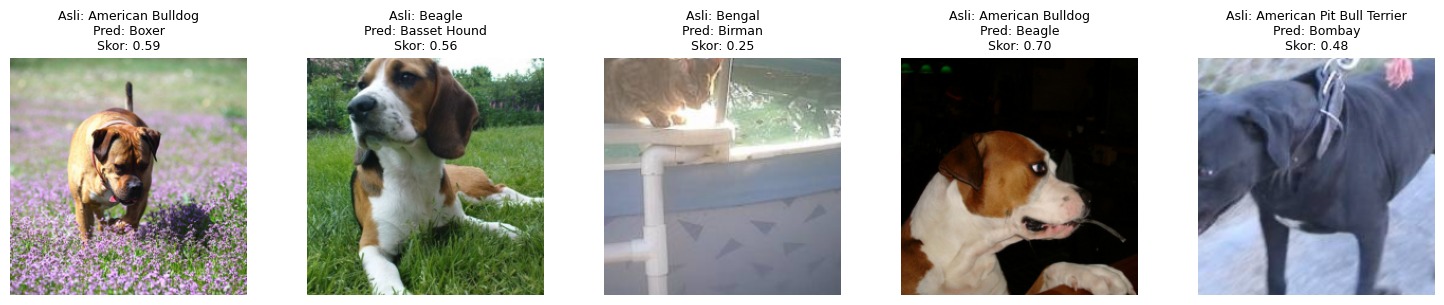

In [10]:
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

torch.manual_seed(seed)
torch.cuda.manual_seed(seed)

model_b3 = buat_model_B3_B4().to(device)
dataset_train_b3 = Subset(dataset_full, idx_train)
loader_train_b3 = DataLoader(dataset_train_b3, batch_size=32, shuffle=True)

optimizer_b3 = torch.optim.AdamW([
    {"params": model_b3.layer4.parameters(), "lr": 1e-4},
    {"params": model_b3.fc.parameters(), "lr": 1e-3},
], weight_decay=1e-2)

model_b3, _, _, _ = latih_model(model_b3, loader_train_b3, loader_val, optimizer_b3, "B3_Khusus_C3")

#visualisasi misklasifikasi
def dapatkan_misklasifikasi_b3(model, loader, jumlah=5):
    model.eval()
    daftar_salah = []

    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            probs = F.softmax(outputs, dim=1)
            scores, preds = torch.max(probs, 1)

            for i in range(len(preds)):
                if preds[i] != labels[i]:
                    #unnormalize image buat plotting
                    img = inputs[i].cpu().numpy().transpose((1, 2, 0))
                    mean = np.array([0.485, 0.456, 0.406])
                    std = np.array([0.229, 0.224, 0.225])
                    img = std * img + mean
                    img = np.clip(img, 0, 1)

                    daftar_salah.append({
                        'gambar': img,
                        'asli': dataset_full.classes[labels[i].item()],
                        'prediksi': dataset_full.classes[preds[i].item()],
                        'skor': scores[i].item()
                    })
                    if len(daftar_salah) == jumlah:
                        break
            if len(daftar_salah) == jumlah:
                break

    #plotting
    fig, axes = plt.subplots(1, jumlah, figsize=(15, 3))
    for i, data in enumerate(daftar_salah):
        axes[i].imshow(data['gambar'])
        axes[i].set_title(f"Asli: {data['asli']}\nPred: {data['prediksi']}\nSkor: {data['skor']:.2f}", fontsize=9)
        axes[i].axis('off')
    plt.tight_layout()
    plt.show()

dapatkan_misklasifikasi_b3(model_b3, loader_test, jumlah=5)


--- Latih: B2_Buat_C5 ---
Epoch  1 | Train Loss: 1.9718 | Val Loss: 1.2757 | Val Acc: 0.7181
Epoch  2 | Train Loss: 1.0152 | Val Loss: 0.7647 | Val Acc: 0.8591
Epoch  3 | Train Loss: 0.6690 | Val Loss: 0.5813 | Val Acc: 0.8523
Epoch  4 | Train Loss: 0.5055 | Val Loss: 0.5066 | Val Acc: 0.8859
Epoch  5 | Train Loss: 0.4041 | Val Loss: 0.4300 | Val Acc: 0.8926
Epoch  6 | Train Loss: 0.3358 | Val Loss: 0.4122 | Val Acc: 0.8926
Epoch  7 | Train Loss: 0.2899 | Val Loss: 0.3778 | Val Acc: 0.8926
Epoch  8 | Train Loss: 0.2625 | Val Loss: 0.3669 | Val Acc: 0.8993
Epoch  9 | Train Loss: 0.2420 | Val Loss: 0.3542 | Val Acc: 0.8993
Epoch 10 | Train Loss: 0.2191 | Val Loss: 0.3437 | Val Acc: 0.9060
Epoch 11 | Train Loss: 0.1924 | Val Loss: 0.3305 | Val Acc: 0.8926
Epoch 12 | Train Loss: 0.1752 | Val Loss: 0.3208 | Val Acc: 0.9128
Epoch 13 | Train Loss: 0.1684 | Val Loss: 0.3167 | Val Acc: 0.8993
Epoch 14 | Train Loss: 0.1595 | Val Loss: 0.3256 | Val Acc: 0.8926
Epoch 15 | Train Loss: 0.1602 | Val

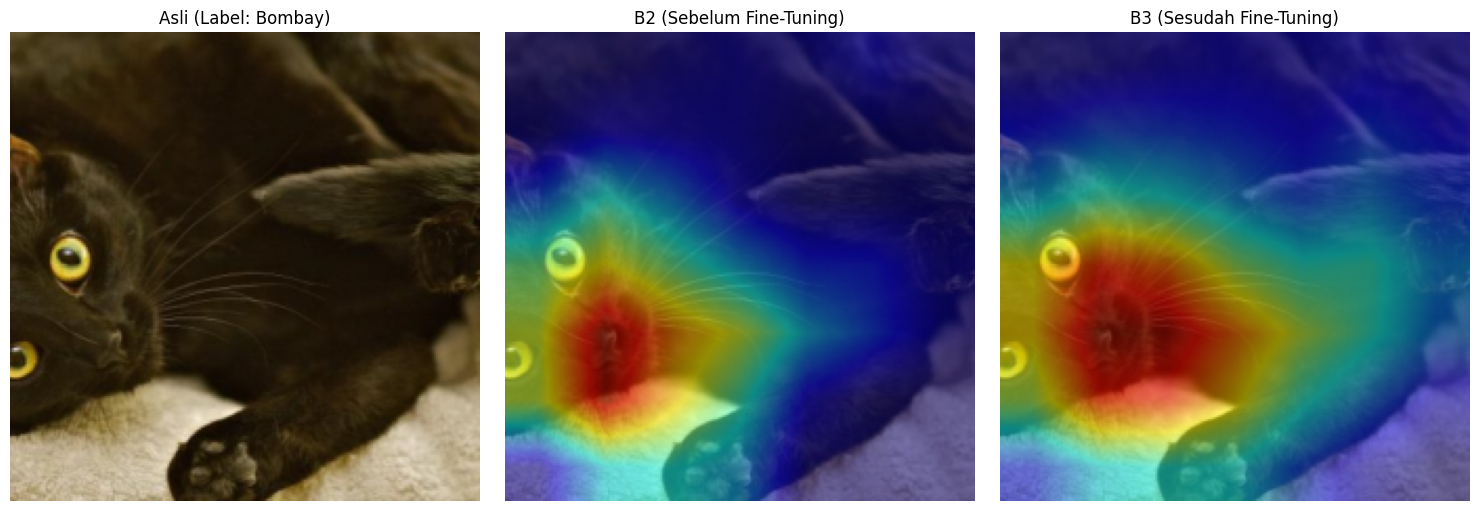

In [14]:
torch.manual_seed(seed)
torch.cuda.manual_seed(seed)

model_b2 = buat_model_B2().to(device)
dataset_train_b2 = Subset(dataset_full, idx_train)
loader_train_b2 = DataLoader(dataset_train_b2, batch_size=32, shuffle=True)

optimizer_b2 = optim.AdamW(filter(lambda p: p.requires_grad, model_b2.parameters()), lr=1e-3, weight_decay=1e-2)
model_b2, _, _, _ = latih_model(model_b2, loader_train_b2, loader_val, optimizer_b2, "B2_Buat_C5")

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

for param in model_b2.layer4.parameters():
    param.requires_grad = True
for param in model_b3.layer4.parameters():
    param.requires_grad = True

# Pastikan model B2 dan B3 ada dalam mode evaluasi
model_b2.eval()
model_b3.eval()

# Tentukan target layer (Layer terakhir dari blok 4 ResNet18)
target_layers_b2 = [model_b2.layer4[-1]]
target_layers_b3 = [model_b3.layer4[-1]]

cam_b2 = GradCAM(model=model_b2, target_layers=target_layers_b2)
cam_b3 = GradCAM(model=model_b3, target_layers=target_layers_b3)

dataiter = iter(loader_test)
inputs, labels = next(dataiter)

#ngambil gambar pertama
idx = 0
input_tensor = inputs[idx:idx+1].to(device)
label = labels[idx].item()
nama_kelas = dataset_full.classes[label]

#denormalize
img = inputs[idx].cpu().numpy().transpose((1, 2, 0))
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])
img = std * img + mean
rgb_img = np.clip(img, 0, 1)

#generate peta grad cam
targets = [ClassifierOutputTarget(label)]
grayscale_cam_b2 = cam_b2(input_tensor=input_tensor, targets=targets)[0, :]
grayscale_cam_b3 = cam_b3(input_tensor=input_tensor, targets=targets)[0, :]

#ngegabungin peta panas dengan gambar asli
cam_image_b2 = show_cam_on_image(rgb_img, grayscale_cam_b2, use_rgb=True)
cam_image_b3 = show_cam_on_image(rgb_img, grayscale_cam_b3, use_rgb=True)

#plot hasil
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(rgb_img)
axes[0].set_title(f"Asli (Label: {nama_kelas})")
axes[0].axis('off')

axes[1].imshow(cam_image_b2)
axes[1].set_title("B2 (Sebelum Fine-Tuning)")
axes[1].axis('off')

axes[2].imshow(cam_image_b3)
axes[2].set_title("B3 (Sesudah Fine-Tuning)")
axes[2].axis('off')

plt.tight_layout()
plt.show()

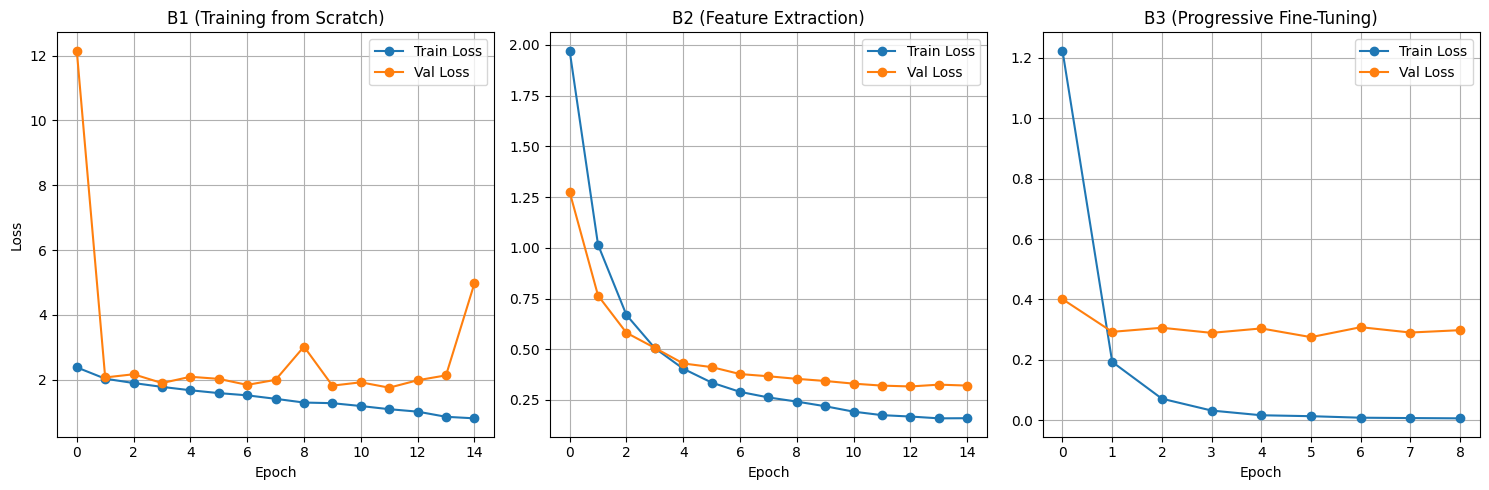

In [16]:
b1_train = [2.3846, 2.0357, 1.9020, 1.7830, 1.6791, 1.5912, 1.5225, 1.4152, 1.2998, 1.2808, 1.1929, 1.0953, 1.0199, 0.8610, 0.8131]
b1_val = [12.1485, 2.0737, 2.1724, 1.9008, 2.0949, 2.0300, 1.8448, 2.0002, 3.0245, 1.8215, 1.9241, 1.7588, 1.9874, 2.1381, 4.9716]

b2_train = [1.9718, 1.0152, 0.6690, 0.5055, 0.4041, 0.3358, 0.2899, 0.2625, 0.2420, 0.2191, 0.1924, 0.1752, 0.1684, 0.1595, 0.1602]
b2_val = [1.2757, 0.7647, 0.5813, 0.5066, 0.4300, 0.4122, 0.3778, 0.3669, 0.3542, 0.3437, 0.3305, 0.3208, 0.3167, 0.3256, 0.3210]

b3_train = [1.2240, 0.1930, 0.0711, 0.0318, 0.0162, 0.0131, 0.0081, 0.0069, 0.0060]
b3_val = [0.4008, 0.2926, 0.3061, 0.2892, 0.3039, 0.2750, 0.3080, 0.2903, 0.2981]

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.plot(b1_train, label='Train Loss', marker='o')
plt.plot(b1_val, label='Val Loss', marker='o')
plt.title('B1 (Training from Scratch)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 3, 2)
plt.plot(b2_train, label='Train Loss', marker='o')
plt.plot(b2_val, label='Val Loss', marker='o')
plt.title('B2 (Feature Extraction)')
plt.xlabel('Epoch')
plt.legend()
plt.grid(True)

plt.subplot(1, 3, 3)
plt.plot(b3_train, label='Train Loss', marker='o')
plt.plot(b3_val, label='Val Loss', marker='o')
plt.title('B3 (Progressive Fine-Tuning)')
plt.xlabel('Epoch')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig('loss_curves.png')
plt.show()